---
title: "Falling Chimney — Independent Work"
description: "Independent study of the internal forces and failure of a falling brick chimney modeled as a rigid rotating body."
---

**FALLING CHIMNEY**

**Juan Camilo Oñoro Araujo, MSc. Mechanical Engineer**
**Universidad del Norte**

*Independent work, not part of a course assignment.*


During this semester I have developed a particular interest in structural and modeling engineering. Recently, I came across an Instagram reel that explained why a falling chimney breaks even before touching the ground. It showed that the maximum bending moment occurs at L/3; however, no assumptions or failure criteria were disclosed or shared. So "I got hands to work": I derived the equations of the model by hand and, after some programming and some boundary conditions for the kinematics, I was able to observe a simplified model of the chimney. With these diagrams, some observations arise:

1. Even if a pinned support (hinge) is assumed at the end of the element, a bending moment appears and acts on the body to satisfy the non-deformable assumption and keep the rotational values constant along the body.
2. No second-order buckling can be included in this linear state: if the end is free to rotate, any lateral/tangential force will generate torque.
3. In some cases, yes, the chimney can break before touching the ground. A small dynamic simulation in Python with the Mohr–Coulomb criterion for the brick (considered uniform and without discontinuities for this post) demonstrates this; however, stiffer materials such as steel will need larger values for the kinematic boundary conditions to break.
4. Ceramics do not resist tension and compression stresses in the same way: that is why the chimney breaks at the section of maximum bending moment, where the tension is reduced by the weight that compresses the inner section.
5. Even if brick chimneys are not commonly used in homes in a hot and humid climate such as Barranquilla's, many industries do use chimneys to evacuate gases. I share a picture where untensioned wires are used to prevent the chimney from falling, acting only when needed.


**GENERAL CALCULATOR**


CROSS-SECTION PROPERTIES
Material density: 1900.0 kg/m^3
Young's modulus: 20.00 GPa
Column length: 8.000 m

Hollow rectangular
Area: 9.600000e-03 m^2
Second moment of area: 1.207200e-04 m^4
Linear mass density: 18.240 kg/m
Total mass: 145.920 kg
Flexural rigidity EI: 2.414400e+06 N m^2

Hollow circular
Area: 5.969026e-03 m^2
Second moment of area: 2.700984e-05 m^4
Linear mass density: 11.341 kg/m
Total mass: 90.729 kg
Flexural rigidity EI: 5.401969e+05 N m^2

HINGE REACTIONS
Section                  Theta       Rt [N]       Rr [N]       Rx [N]       Ry [N]    Resultant [N]
Hollow rectangular         1.0       -6.246     1285.337       16.188     1285.250         1285.352
Hollow rectangular         3.0      -18.729     1283.593       48.474     1282.815         1283.730
Hollow rectangular         5.0      -31.190     1280.108       80.497     1277.955         1280.488
Hollow rectangular        10.0      -62.143     1263.808      158.259     1255.399         1265.335
Hollow circular    

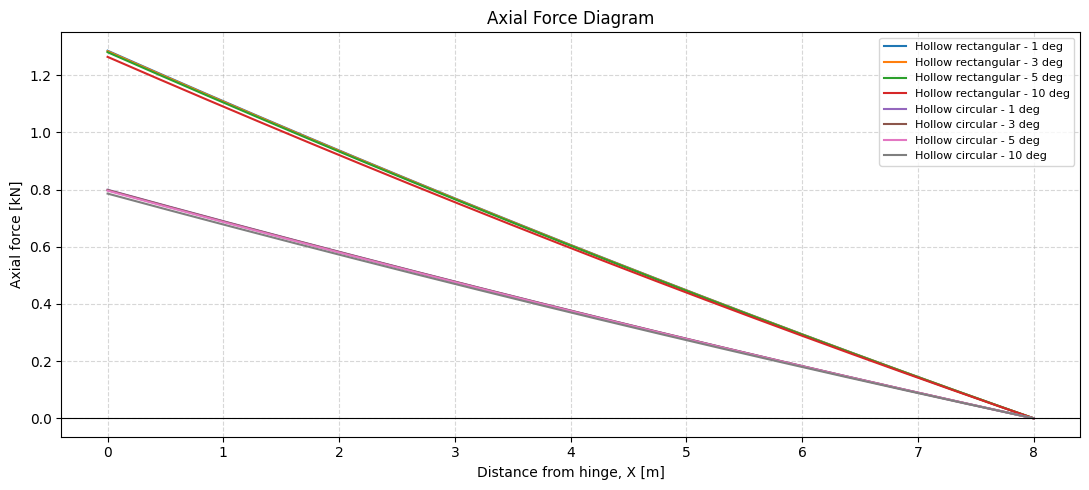

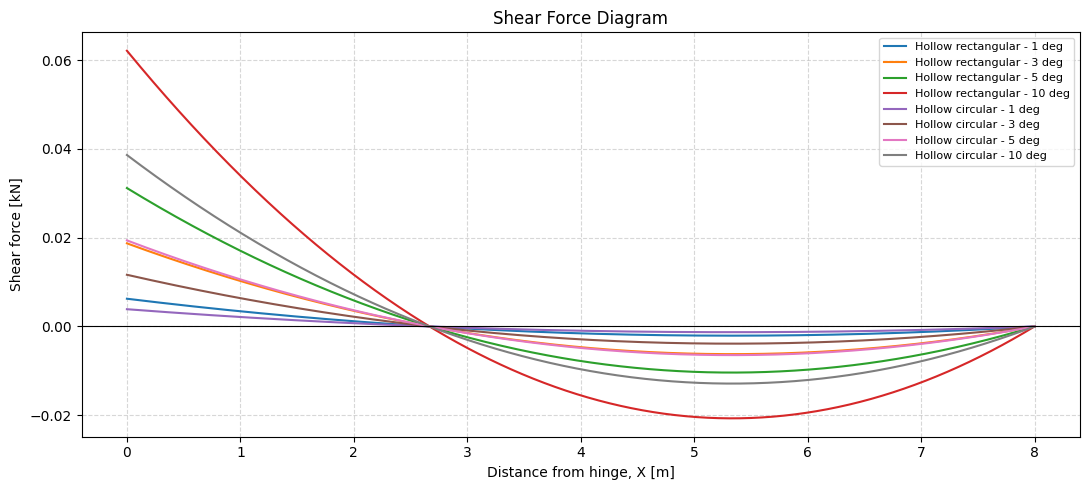

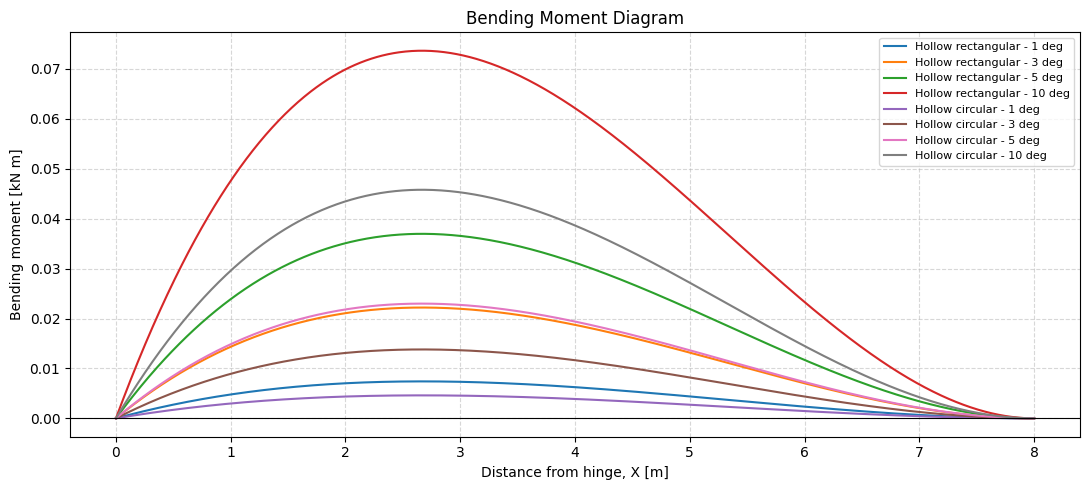

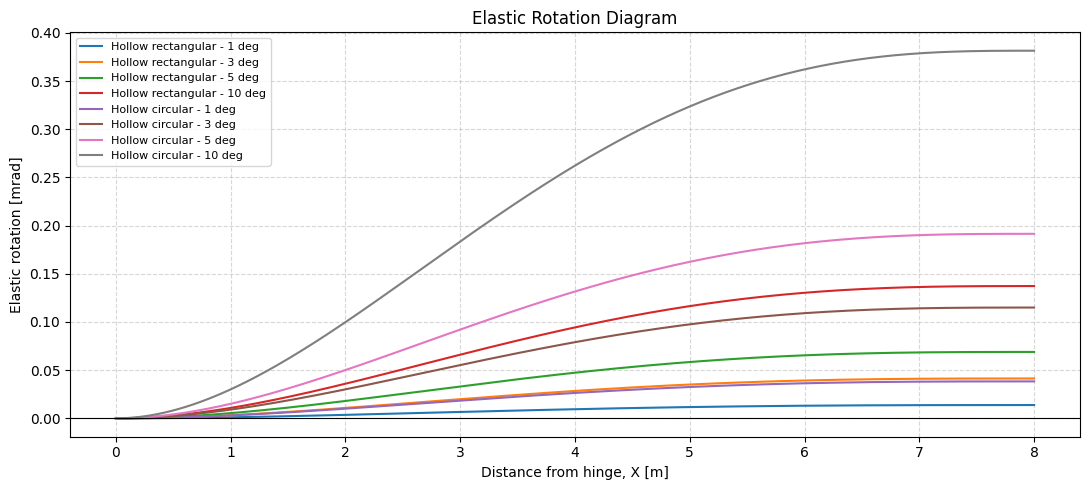

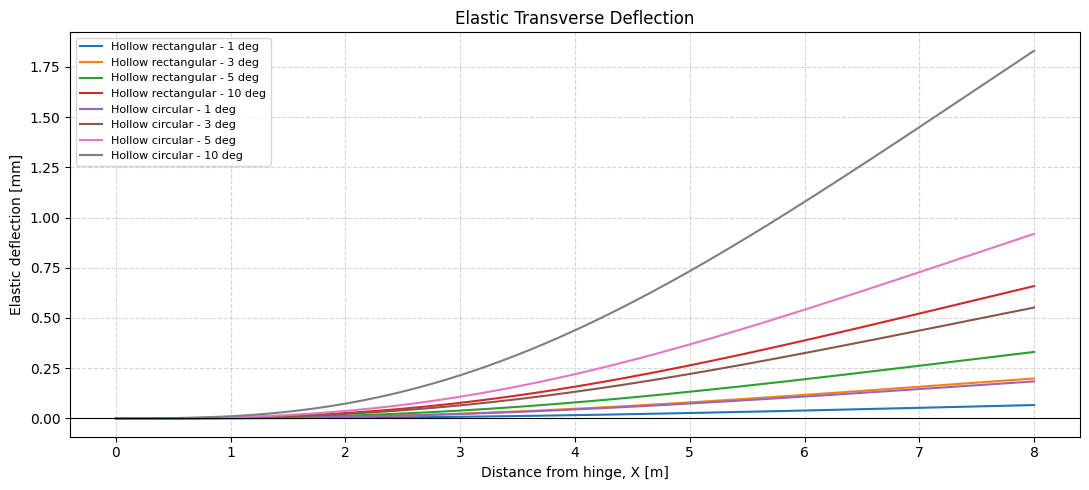


MAXIMUM INTERNAL RESPONSE
Section                  Theta     Max |N| [kN]     Max |V| [kN]     Max |M| [kN m]    Max |phi| [mrad]     Max |v| [mm]
Hollow rectangular         1.0           1.2853           0.0062             0.0074             0.01380          0.06622
Hollow rectangular         3.0           1.2836           0.0187             0.0222             0.04137          0.19859
Hollow rectangular         5.0           1.2801           0.0312             0.0370             0.06890          0.33071
Hollow rectangular        10.0           1.2638           0.0621             0.0737             0.13727          0.65891
Hollow circular            1.0           0.7992           0.0039             0.0046             0.03834          0.18403
Hollow circular            3.0           0.7981           0.0116             0.0138             0.11497          0.55188
Hollow circular            5.0           0.7959           0.0194             0.0230             0.19147          0.91905
Hollo

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. GENERAL INPUT PARAMETERS - SI UNITS
# ============================================================

g = 9.81                       # Gravity [m/s^2]

L = 8                     # Column length [m]
rho = 1900.0                   # Material density [kg/m^3]

omega = 0.5                    # Angular velocity [rad/s]

E = 20e9                      # Young's modulus [Pa]

theta_values_deg = [1, 3, 5, 10]

# ------------------------------------------------------------
# MATERIAL DENSITY EXAMPLES [kg/m^3]
#
# Brick masonry: approximately 1800
# Concrete:      approximately 2400
# Structural steel: 7850
#
# These are illustrative values. Actual density depends on
# material composition, porosity, moisture, and grade.
# ------------------------------------------------------------


# ============================================================
# 2. CROSS-SECTION GEOMETRY
# ============================================================

# ------------------------------------------------------------
# HOLLOW RECTANGULAR SECTION
#
# B = external width [m]
# H = external depth [m]
# t = uniform wall thickness [m]
#
# H is assumed to lie in the bending plane.
# ------------------------------------------------------------

B = 0.20                       # External width [m]
H = 0.30                       # External depth [m]
t_rect = 0.010                 # Wall thickness [m]


# ------------------------------------------------------------
# HOLLOW CIRCULAR SECTION
#
# Do = external diameter [m]
# t = wall thickness [m]
# ------------------------------------------------------------

Do = 0.20                      # External diameter [m]
t_circ = 0.010                 # Wall thickness [m]


# ============================================================
# 3. SECTION PROPERTY CALCULATIONS
# ============================================================

def rectangular_hollow_section(B, H, t, rho, E):

    if min(B, H, t) <= 0:
        raise ValueError("Rectangular dimensions must be positive.")

    if 2*t >= min(B, H):
        raise ValueError("Rectangular wall thickness is too large.")

    # Cross-sectional area [m^2]
    A = B*H - (B - 2*t)*(H - 2*t)

    # Second moment of area about the out-of-plane centroidal axis
    # H is the bending depth [m^4]
    I = (
        B*H**3 -
        (B - 2*t)*(H - 2*t)**3
    ) / 12

    # Linear mass density [kg/m]
    lambda_L = rho*A

    # Total mass [kg]
    mass = lambda_L*L

    return {
        "name": "Hollow rectangular",
        "A": A,
        "I": I,
        "lambda": lambda_L,
        "mass": mass,
        "EI": E*I
    }


def circular_hollow_section(Do, t, rho, E):

    if Do <= 0 or t <= 0:
        raise ValueError("Circular dimensions must be positive.")

    if 2*t >= Do:
        raise ValueError("Circular wall thickness is too large.")

    Di = Do - 2*t

    # Cross-sectional area [m^2]
    A = np.pi/4 * (Do**2 - Di**2)

    # Second moment of area [m^4]
    I = np.pi/64 * (Do**4 - Di**4)

    # Linear mass density [kg/m]
    lambda_L = rho*A

    # Total mass [kg]
    mass = lambda_L*L

    return {
        "name": "Hollow circular",
        "A": A,
        "I": I,
        "lambda": lambda_L,
        "mass": mass,
        "EI": E*I
    }


sections = [
    rectangular_hollow_section(B, H, t_rect, rho, E),
    circular_hollow_section(Do, t_circ, rho, E)
]


# ============================================================
# 4. NUMERICAL INTEGRATION
# ============================================================

def cumulative_trapezoid(y, x):

    result = np.zeros_like(y, dtype=float)

    dx = np.diff(x)

    result[1:] = np.cumsum(
        0.5*(y[:-1] + y[1:])*dx
    )

    return result


# ============================================================
# 5. COLUMN RESPONSE
# ============================================================

def calculate_results(theta_deg, section):

    theta = np.radians(theta_deg)

    lam = section["lambda"]
    EI = section["EI"]
    mass = section["mass"]

    # Angular acceleration [rad/s^2]
    alpha = (3*g/(2*L))*np.sin(theta)

    # --------------------------------------------------------
    # HINGE REACTIONS
    # --------------------------------------------------------

    # Radial reaction [N]
    Rr = mass*(
        g*np.cos(theta) - omega**2*L/2
    )

    # Tangential reaction [N]
    Rt = mass*(
        alpha*L/2 - g*np.sin(theta)
    )

    # Cartesian reactions [N]
    Rx = Rr*np.sin(theta) + Rt*np.cos(theta)

    Ry = Rr*np.cos(theta) - Rt*np.sin(theta)

    # Resultant reaction [N]
    R_resultant = np.sqrt(Rx**2 + Ry**2)

    # --------------------------------------------------------
    # POSITION ALONG COLUMN
    # --------------------------------------------------------

    X = np.linspace(0, L, 1000)

    # --------------------------------------------------------
    # INTERNAL FORCE DIAGRAMS
    # --------------------------------------------------------

    # Axial force: compression positive [N]
    N = lam*(L - X)*(
        g*np.cos(theta) - omega**2*(L + X)/2
    )

    # Shear force [N]
    V = lam*(
        alpha*X**2/2 - g*X*np.sin(theta)
    ) - Rt

    # Bending moment [N*m]
    M = -Rt*X + lam*X*(
        alpha*X**2/6 - g*X*np.sin(theta)/2
    )

    # --------------------------------------------------------
    # ELASTIC ROTATION AND DEFLECTION
    # EULER-BERNOULLI BEAM THEORY
    # --------------------------------------------------------

    # Curvature [1/m]
    curvature = M/EI

    # Elastic rotation relative to hinge tangent [rad]
    phi = cumulative_trapezoid(curvature, X)

    # Elastic deflection relative to hinge tangent [m]
    deflection = cumulative_trapezoid(phi, X)

    # Convenient plotting units
    phi_mrad = phi*1000
    deflection_mm = deflection*1000

    return {
        "theta": theta_deg,
        "section": section["name"],
        "alpha": alpha,
        "Rt": Rt,
        "Rr": Rr,
        "Rx": Rx,
        "Ry": Ry,
        "R_resultant": R_resultant,
        "X": X,
        "N": N,
        "V": V,
        "M": M,
        "phi_mrad": phi_mrad,
        "deflection_mm": deflection_mm
    }


# ============================================================
# 6. PRINT SECTION PROPERTIES
# ============================================================

print("\n" + "="*85)
print("CROSS-SECTION PROPERTIES")
print("="*85)

print(f"Material density: {rho:.1f} kg/m^3")
print(f"Young's modulus: {E/1e9:.2f} GPa")
print(f"Column length: {L:.3f} m")

for section in sections:

    print("\n" + section["name"])

    print(f"Area: {section['A']:.6e} m^2")
    print(f"Second moment of area: {section['I']:.6e} m^4")
    print(f"Linear mass density: {section['lambda']:.3f} kg/m")
    print(f"Total mass: {section['mass']:.3f} kg")
    print(f"Flexural rigidity EI: {section['EI']:.6e} N m^2")


# ============================================================
# 7. CALCULATE ALL CASES
# ============================================================

results = []

for section in sections:

    for theta_deg in theta_values_deg:

        results.append(
            calculate_results(theta_deg, section)
        )


# ============================================================
# 8. PRINT HINGE REACTIONS
# ============================================================

print("\n" + "="*115)
print("HINGE REACTIONS")
print("="*115)

print(
    f"{'Section':<22}"
    f"{'Theta':>8}"
    f"{'Rt [N]':>13}"
    f"{'Rr [N]':>13}"
    f"{'Rx [N]':>13}"
    f"{'Ry [N]':>13}"
    f"{'Resultant [N]':>17}"
)

for r in results:

    print(
        f"{r['section']:<22}"
        f"{r['theta']:8.1f}"
        f"{r['Rt']:13.3f}"
        f"{r['Rr']:13.3f}"
        f"{r['Rx']:13.3f}"
        f"{r['Ry']:13.3f}"
        f"{r['R_resultant']:17.3f}"
    )


# ============================================================
# 9. PLOT INTERNAL FORCE DIAGRAMS
# ============================================================

def plot_diagram(variable, ylabel, title, scale=1):

    plt.figure(figsize=(11, 5))

    for r in results:

        label = f"{r['section']} - {r['theta']} deg"

        plt.plot(
            r["X"],
            r[variable]/scale,
            label=label
        )

    plt.title(title)
    plt.xlabel("Distance from hinge, X [m]")
    plt.ylabel(ylabel)

    plt.axhline(0, color="black", linewidth=0.8)

    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(fontsize=8)

    plt.tight_layout()
    plt.show()


plot_diagram(
    "N",
    "Axial force [kN]",
    "Axial Force Diagram",
    1000
)

plot_diagram(
    "V",
    "Shear force [kN]",
    "Shear Force Diagram",
    1000
)

plot_diagram(
    "M",
    "Bending moment [kN m]",
    "Bending Moment Diagram",
    1000
)


# ============================================================
# 10. ELASTIC ROTATION
# ============================================================

plot_diagram(
    "phi_mrad",
    "Elastic rotation [mrad]",
    "Elastic Rotation Diagram"
)


# ============================================================
# 11. ELASTIC TRANSVERSE DEFLECTION
# ============================================================

plot_diagram(
    "deflection_mm",
    "Elastic deflection [mm]",
    "Elastic Transverse Deflection"
)


# ============================================================
# 12. MAXIMUM RESPONSE TABLE
# ============================================================

print("\n" + "="*125)
print("MAXIMUM INTERNAL RESPONSE")
print("="*125)

print(
    f"{'Section':<22}"
    f"{'Theta':>8}"
    f"{'Max |N| [kN]':>17}"
    f"{'Max |V| [kN]':>17}"
    f"{'Max |M| [kN m]':>19}"
    f"{'Max |phi| [mrad]':>20}"
    f"{'Max |v| [mm]':>17}"
)

for r in results:

    print(
        f"{r['section']:<22}"
        f"{r['theta']:8.1f}"
        f"{np.max(np.abs(r['N']))/1000:17.4f}"
        f"{np.max(np.abs(r['V']))/1000:17.4f}"
        f"{np.max(np.abs(r['M']))/1000:19.4f}"
        f"{np.max(np.abs(r['phi_mrad'])):20.5f}"
        f"{np.max(np.abs(r['deflection_mm'])):17.5f}"
    )


# ============================================================
# 13. MOMENT BOUNDARY CONDITION CHECK
# ============================================================

print("\n" + "="*75)
print("MOMENT BOUNDARY CONDITION CHECK")
print("="*75)

for r in results:

    print(
        f"{r['section']:<22} "
        f"Theta = {r['theta']:5.1f} deg | "
        f"M(0) = {r['M'][0]:.6e} N m | "
        f"M(L) = {r['M'][-1]:.6e} N m"
    )


**DYNAMIC SIMULATION**

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# ============================================================
# 1. PARÁMETROS DE ENTRADA
# ============================================================

g = 9.81

# Geometría: sección rectangular maciza
L = 8             # Longitud de la columna [m]
B = 0.30             # Ancho de la sección [m]
H = 0.30             # Altura de la sección [m], dirección de flexión

A = B * H
I = B * H**3 / 12
c = H / 2

# Material: valores ilustrativos para ladrillo de arcilla
rho = 1800           # Densidad [kg/m3]
E = 20e9              # Módulo de elasticidad [Pa]

fc = 11e6            # Resistencia a compresión [Pa]
ft = 1e6             # Resistencia a tensión [Pa]

# Condiciones iniciales
theta0 = 0.001       # Ángulo inicial [rad]
rpm0 = 0.013         # Velocidad angular inicial [rpm]
omega0 = rpm0 * 2*np.pi / 60  # [rad/s]

# Integración temporal
dt = 0.005           # Paso de tiempo [s]
t_max = 60.0         # Tiempo máximo de seguridad [s]

# Resolución espacial
nx = 151
ny = 41

x = np.linspace(0, L, nx)
y = np.linspace(-c, c, ny)

# Masa por unidad de longitud y masa total
lam = rho * A
m = lam * L

# Momento de inercia de masa de la barra respecto al apoyo
J = m * L**2 / 3

# ============================================================
# 2. ECUACIONES DEL MOVIMIENTO
# ============================================================

def angular_acceleration(theta):
    """
    Barra uniforme articulada en la base.
    Modelo de cuerpo rígido sometido a gravedad.
    """
    return 3*g/(2*L) * np.sin(theta)


def derivatives(state):
    theta, omega = state
    alpha = angular_acceleration(theta)

    return np.array([omega, alpha])


def rk4_step(state, dt):
    k1 = derivatives(state)
    k2 = derivatives(state + 0.5*dt*k1)
    k3 = derivatives(state + 0.5*dt*k2)
    k4 = derivatives(state + dt*k3)

    return state + (dt/6)*(k1 + 2*k2 + 2*k3 + k4)


# ============================================================
# 3. CRITERIO DE COULOMB-MOHR
# ============================================================

def coulomb_mohr_index(sigma1, sigma3):
    """
    Esfuerzos principales ordenados:
    sigma1 >= sigma3.

    Convención:
    tensión positiva, compresión negativa.

    El índice alcanza 1 cuando se llega a la envolvente
    de falla de Coulomb-Mohr.
    """

    result = np.zeros_like(sigma1, dtype=float)

    tension = (sigma3 >= 0)
    compression = (sigma1 <= 0)
    mixed = ~(tension | compression)

    result[tension] = sigma1[tension] / ft

    result[compression] = -sigma3[compression] / fc

    result[mixed] = (
        sigma1[mixed]/ft - sigma3[mixed]/fc
    )

    return result


def principal_stresses(sigma, tau):
    """
    Estado plano de esfuerzos:
    sigma_x = sigma
    sigma_y = 0
    tau_xy = tau
    """

    center = sigma / 2
    radius = np.sqrt((sigma/2)**2 + tau**2)

    sigma1 = center + radius
    sigma3 = center - radius

    return sigma1, sigma3


# ============================================================
# 4. REACCIONES Y ESFUERZOS INTERNOS
# ============================================================

def calculate_state(theta, omega):

    alpha = angular_acceleration(theta)

    # Reacciones en coordenadas radial y tangencial
    Rt = m*(alpha*L/2 - g*np.sin(theta))

    Rr = m*(-omega**2*L/2 + g*np.cos(theta))

    # Reacciones cartesianas
    Rx = Rr*np.sin(theta) + Rt*np.cos(theta)
    Ry = Rr*np.cos(theta) - Rt*np.sin(theta)

    # Fuerzas internas
    N = lam*(L-x)*(
        g*np.cos(theta) - (L+x)*omega**2/2
    )

    V = lam*(
        alpha*x**2/2 - g*x*np.sin(theta)
    ) - Rt

    M = (
        lam*g*np.sin(theta)/(4*L)
        * x*(L-x)**2
    )

    # --------------------------------------------------------
    # ESFUERZOS EN LA SECCIÓN
    # --------------------------------------------------------

    # N positivo significa compresión.
    # Para el criterio, tensión es positiva.
    sigma = (
        -N[:, None]/A
        + M[:, None]*y[None, :]/I
    )

    # Distribución parabólica de cortante para sección
    # rectangular maciza.
    tau = (
        1.5*V[:, None]/A
        * (1 - (y[None, :]/c)**2)
    )

    # Esfuerzos principales combinados
    s1, s3 = principal_stresses(sigma, tau)

    FI_combined = coulomb_mohr_index(s1, s3)

    # Utilización debida únicamente a axial-flexión
    sn1, sn3 = principal_stresses(sigma, np.zeros_like(sigma))
    FI_normal = coulomb_mohr_index(sn1, sn3)

    # Utilización debida únicamente a cortante
    ss1, ss3 = principal_stresses(
        np.zeros_like(tau), tau
    )
    FI_shear = coulomb_mohr_index(ss1, ss3)

    # Máxima utilización combinada en cada sección x
    FI_x = np.max(FI_combined, axis=1)

    # Máximos individuales por sección
    FI_normal_x = np.max(FI_normal, axis=1)
    FI_shear_x = np.max(FI_shear, axis=1)

    # Decidir cuál contribución aislada gobierna
    governing = np.where(
        FI_normal_x >= FI_shear_x,
        0, 1
    )

    # Punto crítico de toda la columna
    critical_flat = np.argmax(FI_combined)
    ix, iy = np.unravel_index(
        critical_flat, FI_combined.shape
    )

    return {
        "alpha": alpha,
        "Rx": Rx,
        "Ry": Ry,
        "Rr": Rr,
        "Rt": Rt,
        "N": N,
        "V": V,
        "M": M,
        "FI_x": FI_x,
        "FI_normal_x": FI_normal_x,
        "FI_shear_x": FI_shear_x,
        "governing": governing,
        "FI_max": FI_combined[ix, iy],
        "x_critical": x[ix],
        "y_critical": y[iy],
        "sigma_critical": sigma[ix, iy],
        "tau_critical": tau[ix, iy]
    }


# ============================================================
# 5. SIMULACIÓN TEMPORAL Y DETECCIÓN DE FALLA
# ============================================================

state = np.array([theta0, omega0])

times = []
history = []

failure = False
fall_complete = False

t = 0.0

while t <= t_max:

    theta, omega = state

    result = calculate_state(theta, omega)

    times.append(t)
    history.append(result)

    # Primero se revisa la falla
    if result["FI_max"] >= 1.0:
        failure = True
        break

    # Después se revisa si alcanzó 90 grados
    if theta >= np.pi/2:
        fall_complete = True
        break

    # Integración del siguiente paso
    state = rk4_step(state, dt)
    t += dt


times = np.array(times)

# Convertir resultados en arreglos
theta_history = np.array([
    np.arctan2(
        np.sin(theta0), np.cos(theta0)
    ) for _ in times
])  # Se reemplaza abajo por la integración reconstruida

# Reconstrucción del ángulo y velocidad para visualización
states = [np.array([theta0, omega0])]
for i in range(1, len(times)):
    states.append(rk4_step(states[-1], dt))

theta_history = np.array([s[0] for s in states])
omega_history = np.array([s[1] for s in states])

# ============================================================
# 6. RESULTADO FINAL
# ============================================================

last = history[-1]

if failure:
    print("\n========== FALLA DE LA COLUMNA ==========")
    print(f"Tiempo de falla: {times[-1]:.3f} s")
    print(f"Ángulo de falla: {np.degrees(theta_history[-1]):.4f}°")
    print(f"Posición crítica desde la articulación: "
          f"{last['x_critical']:.4f} m")
    print(f"Coordenada crítica en la sección: "
          f"{last['y_critical']:.4f} m")
    print(f"Índice de falla combinado: {last['FI_max']:.4f}")
    print(f"Esfuerzo normal crítico: "
          f"{last['sigma_critical']/1e6:.4f} MPa")
    print(f"Esfuerzo cortante crítico: "
          f"{last['tau_critical']/1e6:.4f} MPa")

    print("\nReacciones en el instante de falla:")
    print(f"Rx = {last['Rx']/1000:.4f} kN")
    print(f"Ry = {last['Ry']/1000:.4f} kN")
    print(f"Radial = {last['Rr']/1000:.4f} kN")
    print(f"Tangencial = {last['Rt']/1000:.4f} kN")

elif fall_complete:
    print("\n========== CAÍDA COMPLETADA ==========")
    print(f"Tiempo: {times[-1]:.3f} s")
    print(f"Ángulo final: {np.degrees(theta_history[-1]):.4f}°")
    print(f"Índice de falla final: {last['FI_max']:.4f}")

else:
    print("Se alcanzó el tiempo máximo de simulación.")


# ============================================================
# 7. PREPARAR DATOS PARA ANIMACIÓN
# ============================================================

N_hist = np.array([r["N"] for r in history])
V_hist = np.array([r["V"] for r in history])
M_hist = np.array([r["M"] for r in history])

FI_hist = np.array([r["FI_x"] for r in history])
FI_normal_hist = np.array([
    r["FI_normal_x"] for r in history
])
FI_shear_hist = np.array([
    r["FI_shear_x"] for r in history
])

Rx_hist = np.array([r["Rx"] for r in history])
Ry_hist = np.array([r["Ry"] for r in history])

# ============================================================
# 8. CONFIGURAR GRÁFICAS
# ============================================================

fig, axs = plt.subplots(2, 3, figsize=(16, 9))
fig.subplots_adjust(
    hspace=0.35, wspace=0.30, top=0.88
)

axN, axV, axM = axs[0]
axFI, axR, axMotion = axs[1]

# Fuerza axial
lineN, = axN.plot([], [], linewidth=2)
axN.set_title("Axial force N(x)")
axN.set_xlabel("Position x [m]")
axN.set_ylabel("N [kN]")
axN.grid(True)
axN.axhline(0, color="black", linewidth=0.7)

# Cortante
lineV, = axV.plot([], [], linewidth=2)
axV.set_title("Shear force V(x)")
axV.set_xlabel("Position x [m]")
axV.set_ylabel("V [kN]")
axV.grid(True)
axV.axhline(0, color="black", linewidth=0.7)

# Momento
lineM, = axM.plot([], [], linewidth=2)
axM.set_title("Bending moment M(x)")
axM.set_xlabel("Position x [m]")
axM.set_ylabel("M [kN m]")
axM.grid(True)
axM.axhline(0, color="black", linewidth=0.7)

# Índices de falla
lineFI, = axFI.plot([], [], linewidth=2,
                    label="Combined Coulomb-Mohr")
lineFIn, = axFI.plot([], [], "--",
                     label="Axial-flexure only")
lineFIs, = axFI.plot([], [], ":",
                     label="Transverse shear only")

axFI.axhline(1, color="red", linestyle="--",
             label="Failure threshold")
axFI.set_title("Failure utilization along column")
axFI.set_xlabel("Position x [m]")
axFI.set_ylabel("Failure index [-]")
axFI.grid(True)
axFI.legend(fontsize=8)

# Reacciones a lo largo del tiempo
lineRx, = axR.plot([], [], label="Rx")
lineRy, = axR.plot([], [], label="Ry")
pointRx, = axR.plot([], [], "o")
pointRy, = axR.plot([], [], "o")

axR.set_title("Support reactions")
axR.set_xlabel("Time [s]")
axR.set_ylabel("Reaction [kN]")
axR.grid(True)
axR.legend()

# Movimiento angular
lineTheta, = axMotion.plot([], [], label="Angle [deg]")
lineOmega, = axMotion.plot([], [], label="Angular velocity [rpm]")

axMotion.set_title("Rotational motion")
axMotion.set_xlabel("Time [s]")
axMotion.set_ylabel("Angle [deg] / velocity [rpm]")
axMotion.grid(True)
axMotion.legend()

# Límites de los ejes
def safe_limits(data, scale=1.15):
    maximum = np.max(np.abs(data))
    if maximum < 1e-12:
        maximum = 1.0
    return -scale*maximum, scale*maximum

axN.set_xlim(0, L)
axV.set_xlim(0, L)
axM.set_xlim(0, L)
axFI.set_xlim(0, L)

axN.set_ylim(*safe_limits(N_hist/1000))
axV.set_ylim(*safe_limits(V_hist/1000))
axM.set_ylim(*safe_limits(M_hist/1000))

fi_max_plot = max(1.1, np.max(FI_hist)*1.15)
axFI.set_ylim(0, fi_max_plot)

axR.set_xlim(0, max(times[-1], dt))
axR.set_ylim(*safe_limits(
    np.concatenate([Rx_hist, Ry_hist])/1000
))

axMotion.set_xlim(0, max(times[-1], dt))
axMotion.set_ylim(
    min(-5, np.min(np.degrees(theta_history))*1.1),
    100
)

# ============================================================
# 9. ACTUALIZACIÓN DE CADA INSTANTE
# ============================================================

counter = fig.suptitle("", fontsize=14)

def update(frame):

    current_t = times[frame]
    current = history[frame]

    # Diagramas internos
    lineN.set_data(x, N_hist[frame]/1000)
    lineV.set_data(x, V_hist[frame]/1000)
    lineM.set_data(x, M_hist[frame]/1000)

    # Índices de falla
    lineFI.set_data(x, FI_hist[frame])
    lineFIn.set_data(x, FI_normal_hist[frame])
    lineFIs.set_data(x, FI_shear_hist[frame])

    # Reacciones
    lineRx.set_data(times[:frame+1], Rx_hist[:frame+1]/1000)
    lineRy.set_data(times[:frame+1], Ry_hist[:frame+1]/1000)

    pointRx.set_data(
        [current_t], [Rx_hist[frame]/1000]
    )
    pointRy.set_data(
        [current_t], [Ry_hist[frame]/1000]
    )

    # Movimiento
    lineTheta.set_data(
        times[:frame+1],
        np.degrees(theta_history[:frame+1])
    )

    lineOmega.set_data(
        times[:frame+1],
        omega_history[:frame+1]*60/(2*np.pi)
    )

    # Contador de tiempo y datos instantáneos
    counter.set_text(
        f"TIME = {current_t:.3f} s   |   "
        f"ANGLE = {np.degrees(theta_history[frame]):.3f}°   |   "
        f"OMEGA = {omega_history[frame]*60/(2*np.pi):.4f} rpm   |   "
        f"FI = {current['FI_max']:.3f}"
    )

    # Ajustar límite superior del gráfico de falla si es necesario
    axFI.set_ylim(0, max(1.1, np.max(FI_hist[:frame+1])*1.15))

    return (
        lineN, lineV, lineM,
        lineFI, lineFIn, lineFIs,
        lineRx, lineRy, pointRx, pointRy,
        lineTheta, lineOmega, counter
    )


# Reducir frames si la simulación es muy larga
step_animation = max(1, len(times)//1000)
frames = range(0, len(times), step_animation)

ani = FuncAnimation(
    fig,
    update,
    frames=frames,
    interval=30,
    blit=False,
    repeat=False
)

# Guardar la animación completa como MP4 (to_jshtml supera el límite de 20 MB y corta los cuadros)
ani.save("falling_chimney_simulation.mp4", writer="ffmpeg", fps=33, dpi=100)
plt.close(fig)



========== FALLA DE LA COLUMNA ==========
Tiempo de falla: 5.425 s
Ángulo de falla: 85.7694°
Posición crítica desde la articulación: 2.5600 m
Coordenada crítica en la sección: 0.1500 m
Índice de falla combinado: 1.0029
Esfuerzo normal crítico: 1.0029 MPa
Esfuerzo cortante crítico: 0.0000 MPa

Reacciones en el instante de falla:
Rx = -16.9142 kN
Ry = 1.9273 kN
Radial = -16.7259 kN
Tangencial = -3.1698 kN


```{figure} falling_chimney_simulation.mp4
:label: fig-falling-chimney-simulation

Dynamic simulation of the falling chimney until failure: axial force, shear force and bending moment diagrams, Mohr–Coulomb failure index along the column, support reactions and rotational motion.
```
